In [1]:
!pip install -q nltk qalsadi beautifulsoup4 requests
import nltk; nltk.download('stopwords', quiet=True)

True

In [2]:
%%writefile scraper.py
import csv
import re
import sys
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from urllib.parse import urljoin

import requests
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) TD3-student-scraper"}
OUT = Path(__file__).parent / "data" / "raw_articles.csv"

HESPRESS = [
    ("hespress", "economy", "https://www.hespress.com/economie/page/{}", 30),
    ("hespress", "society", "https://www.hespress.com/societe/page/{}", 10),
    ("hespress", "sport", "https://www.hespress.com/sport/page/{}", 10),
    ("hespress", "culture", "https://www.hespress.com/art-et-culture/page/{}", 10),
]
ALJAZEERA = [
    ("aljazeera", "economy", "https://www.aljazeera.net/ebusiness/", "ebusiness"),
    ("aljazeera", "sport", "https://www.aljazeera.net/sport/", "sport"),
    ("aljazeera", "culture", "https://www.aljazeera.net/culture/", "culture"),
    ("aljazeera", "society", "https://www.aljazeera.net/lifestyle/", "lifestyle"),
]

session = requests.Session()
session.headers.update(HEADERS)


def get(url, retries=2):
    for attempt in range(retries + 1):
        try:
            r = session.get(url, timeout=12)
            if r.status_code == 200:
                r.encoding = "utf-8"
                return r.text
            if r.status_code in (403, 404):
                return None
        except requests.RequestException:
            pass
        time.sleep(1 + attempt)
    return None


def hespress_links(template, pages):
    links = []
    for p in range(1, pages + 1):
        html = get(template.format(p))
        if not html:
            continue
        soup = BeautifulSoup(html, "html.parser")
        for a in soup.select("a[href]"):
            href = a["href"]
            if re.match(r"https://www\.hespress\.com/[^/]+-\d+\.html$", href):
                links.append(href)
        time.sleep(0.3)
    return list(dict.fromkeys(links))


def aljazeera_links(url, slug):
    html = get(url)
    if not html:
        return []
    soup = BeautifulSoup(html, "html.parser")
    pat = re.compile(rf"^/{slug}/\d{{4}}/\d{{1,2}}/\d{{1,2}}/")
    links = [urljoin(url, a["href"]) for a in soup.select("a[href]") if pat.match(a["href"])]
    return list(dict.fromkeys(links))


def parse_article(url, source):
    html = get(url)
    if not html:
        return None
    soup = BeautifulSoup(html, "html.parser")
    body = soup.select_one("div.article-content" if source == "hespress" else "div.wysiwyg")
    if body is None:
        return None
    paragraphs = [p.get_text(" ", strip=True) for p in body.find_all("p")]
    paragraphs = [p for p in paragraphs if len(p) > 30]
    h1 = soup.find("h1")
    title = h1.get_text(" ", strip=True) if h1 else ""
    text = "\n".join(paragraphs)
    if len(text) < 200:
        return None
    return {"title": title, "text": text}


def main():
    OUT.parent.mkdir(parents=True, exist_ok=True)
    jobs = []
    for source, section, tpl, pages in HESPRESS:
        links = hespress_links(tpl, pages)
        print(f"{source}/{section}: {len(links)} links", flush=True)
        jobs += [(source, section, u) for u in links]
    for source, section, url, slug in ALJAZEERA:
        links = aljazeera_links(url, slug)
        print(f"{source}/{section}: {len(links)} links", flush=True)
        jobs += [(source, section, u) for u in links]

    seen, rows = set(), []
    jobs = [j for j in jobs if not (j[2] in seen or seen.add(j[2]))]
    with ThreadPoolExecutor(max_workers=6) as pool:
        futures = {pool.submit(parse_article, url, src): (src, sec, url) for src, sec, url in jobs}
        for i, fut in enumerate(as_completed(futures), 1):
            src, sec, url = futures[fut]
            art = fut.result()
            if art:
                rows.append({"source": src, "section": sec, "url": url, **art})
            if i % 50 == 0:
                print(f"  parsed {i}/{len(jobs)} -> kept {len(rows)}", flush=True)

    with OUT.open("w", encoding="utf-8", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["source", "section", "url", "title", "text"])
        w.writeheader()
        w.writerows(rows)
    print(f"saved {len(rows)} articles -> {OUT}")
    return 0


if __name__ == "__main__":
    sys.exit(main())

Overwriting scraper.py


In [3]:
from pathlib import Path
if not Path('data/raw_articles.csv').exists():
    !python scraper.py
import pandas as pd
raw = pd.read_csv('data/raw_articles.csv')
print(raw.shape)
raw.groupby(['source', 'section']).size().unstack(fill_value=0)

(864, 5)


section,culture,economy,society,sport
source,,,,
aljazeera,20,71,16,35
hespress,120,363,119,120


In [4]:
%%writefile preprocessing.py
import json
import re
from pathlib import Path

from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

DATA = Path(__file__).parent / "data"
LEMMA_CACHE = DATA / "lemma_cache.json"

DIACRITICS = re.compile(r"[ؗ-ًؚ-ْٰ]")
TATWEEL = "ـ"
NON_ARABIC = re.compile(r"[^ء-ي\s]")
URL = re.compile(r"https?://\S+|www\.\S+")
SPACES = re.compile(r"\s+")


def normalize(text: str) -> str:
    text = DIACRITICS.sub("", text).replace(TATWEEL, "")
    text = re.sub("[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي").replace("ؤ", "و").replace("ئ", "ي").replace("ة", "ه")
    return text


def clean(text: str) -> str:
    text = URL.sub(" ", text)
    text = DIACRITICS.sub("", text).replace(TATWEEL, "")
    text = NON_ARABIC.sub(" ", text)
    return SPACES.sub(" ", text).strip()


def tokenize(text: str) -> list[str]:
    return [t for t in clean(text).split() if len(t) > 1]


STOPWORDS = {normalize(w) for w in stopwords.words("arabic")}
_stemmer = ISRIStemmer()


def stem(token: str) -> str:
    return _stemmer.stem(token)


class Lemmatizer:

    def __init__(self):
        import qalsadi.lemmatizer

        self._lem = qalsadi.lemmatizer.Lemmatizer()
        self.cache = json.loads(LEMMA_CACHE.read_text("utf-8")) if LEMMA_CACHE.exists() else {}

    def __call__(self, token: str) -> str:
        if token not in self.cache:
            try:
                lemma = self._lem.lemmatize(token) or token
            except Exception:
                lemma = token
            self.cache[token] = lemma if isinstance(lemma, str) else token
        return self.cache[token]

    def save(self):
        LEMMA_CACHE.parent.mkdir(parents=True, exist_ok=True)
        LEMMA_CACHE.write_text(json.dumps(self.cache, ensure_ascii=False), "utf-8")


class Pipeline:

    def __init__(self, use_lemmas: bool = True):
        self.lemmatizer = Lemmatizer() if use_lemmas else None

    def __call__(self, text: str) -> list[str]:
        out = []
        for tok in tokenize(text):
            if normalize(tok) in STOPWORDS:
                continue
            lemma = self.lemmatizer(tok) if self.lemmatizer else tok
            lemma = normalize(lemma)
            if len(lemma) > 1 and lemma not in STOPWORDS:
                out.append(lemma)
        return out

    def save(self):
        if self.lemmatizer:
            self.lemmatizer.save()


CLASSES = ["low", "medium", "high"]
BINS = (4.0, 7.0)


def discretize(score: float) -> int:
    return 0 if score < BINS[0] else (1 if score < BINS[1] else 2)


if __name__ == "__main__":
    sample = "ارتفعت أسعارُ المحروقات في الأسواق المغربية، وتراجعت بورصة الدار البيضاء بنسبة 2% بسبب التضخم."
    print("clean    :", clean(sample))
    print("normalize:", normalize(clean(sample)))
    print("tokens   :", tokenize(sample))
    print("stems    :", [stem(t) for t in tokenize(sample)])
    print("pipeline :", Pipeline()(sample))
    print("discretize(3, 5.5, 8):", [CLASSES[discretize(s)] for s in (3, 5.5, 8)])

Overwriting preprocessing.py


In [5]:
!python preprocessing.py

clean    : ارتفعت أسعار المحروقات في الأسواق المغربية وتراجعت بورصة الدار البيضاء بنسبة بسبب التضخم
normalize: ارتفعت اسعار المحروقات في الاسواق المغربيه وتراجعت بورصه الدار البيضاء بنسبه بسبب التضخم
tokens   : ['ارتفعت', 'أسعار', 'المحروقات', 'في', 'الأسواق', 'المغربية', 'وتراجعت', 'بورصة', 'الدار', 'البيضاء', 'بنسبة', 'بسبب', 'التضخم']
stems    : ['رفع', 'سعر', 'حرق', 'في', 'سوق', 'غرب', 'رجع', 'ورص', 'دار', 'يضء', 'نسب', 'سبب', 'ضخم']
pipeline : ['ارتفع', 'سعار', 'محروق', 'سوق', 'مغرب', 'تراجع', 'بورصه', 'دار', 'بيضاء', 'نسب', 'سبب', 'تضخم']
discretize(3, 5.5, 8): ['low', 'medium', 'high']


In [6]:
%%writefile build_dataset.py
import json
import re

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as l2

from preprocessing import DATA, Pipeline

MIN_WORDS, MAX_WORDS = 40, 120

CORE = """اقتصاد اقتصادي الاقتصادية تضخم بورصة استثمار مستثمر ميزانية ضريبة ضرائب بنك البنوك
مصرف صرف الدرهم دولار أورو يورو عملة الناتج الداخلي نمو تجارة تجاري صادرات واردات عجز
ديون قرض قروض فائدة أسهم سندات مالية المالية تمويل أرباح إيرادات مداخيل رقم المعاملات
شركة الشركات مقاولة المقاولات أسعار الأسعار السوق الأسواق نفط النفط الغاز المحروقات
بطالة التشغيل الأجور الرواتب الاستهلاك القدرة الشرائية الاستيراد التصدير الجمارك
الصناعة الفلاحة السياحة العقار العقارات الطاقة البترول الذهب التداولات المؤشر رأسمال
الاستثمارات المالي النقدي الفائدة القطاع الخاص الخوصصة الدعم الإنتاج التنمية الاقتصادية""".split()
GENERAL = """مليون مليار نسبة بالمائة المائة قطاع سعر كلفة تكلفة ارتفاع انخفاض تراجع ارتفعت
انخفضت مشروع مشاريع سوق إنتاج منتجات خدمات مستهلك المستهلكين حكومة وزارة المالية""".split()


def split_passages(text: str) -> list[str]:
    paragraphs = [p.strip() for p in text.split("\n") if p.strip()]
    passages, buf = [], []
    for p in paragraphs:
        words = p.split()
        while len(words) > MAX_WORDS:
            cut = MAX_WORDS
            for i in range(MAX_WORDS, MIN_WORDS, -1):
                if re.search(r"[.!؟?]$", words[i - 1]):
                    cut = i
                    break
            buf += words[:cut]
            passages.append(" ".join(buf))
            buf, words = [], words[cut:]
        buf += words
        if len(buf) >= MIN_WORDS:
            passages.append(" ".join(buf))
            buf = []
    if len(buf) >= MIN_WORDS // 2 and passages:
        passages[-1] += " " + " ".join(buf)
    elif len(buf) >= MIN_WORDS:
        passages.append(" ".join(buf))
    return [p for p in passages if MIN_WORDS <= len(p.split()) <= MAX_WORDS + MIN_WORDS]


def lexicon_scores(token_lists, pipe):
    weights = {}
    for words, w in ((GENERAL, 1.0), (CORE, 2.0)):
        for word in words:
            for lemma in pipe(word):
                weights[lemma] = max(weights.get(lemma, 0), w)
    dens = np.array([sum(weights.get(t, 0) for t in toks) / max(len(toks), 1) for toks in token_lists])
    k = 8.0
    return 1 - np.exp(-k * dens), weights


def tfidf_scores(token_lists, is_economy):
    vec = TfidfVectorizer(analyzer=lambda toks: toks, min_df=2, sublinear_tf=True)
    X = vec.fit_transform(token_lists)
    c_eco = l2(np.asarray(X[is_economy].mean(axis=0)))
    c_oth = l2(np.asarray(X[~is_economy].mean(axis=0)))
    raw = (X @ c_eco.T).ravel() - (X @ c_oth.T).ravel()
    lo, hi = np.percentile(raw, [2, 98])
    return np.clip((raw - lo) / (hi - lo), 0, 1)


def main():
    raw = pd.read_csv(DATA / "raw_articles.csv")
    rows = []
    for art in raw.itertuples():
        for i, passage in enumerate(split_passages(art.text)):
            rows.append({"Text": passage, "source": art.source, "section": art.section,
                         "url": art.url, "passage_id": i})
    df = pd.DataFrame(rows).drop_duplicates("Text").reset_index(drop=True)
    print(f"{len(raw)} articles -> {len(df)} passages")

    pipe = Pipeline()
    tokens = []
    for i, t in enumerate(df.Text):
        tokens.append(pipe(t))
        if i % 500 == 0:
            print(f"  preprocessed {i}/{len(df)} (lemma cache {len(pipe.lemmatizer.cache)})", flush=True)
            pipe.save()
    pipe.save()

    lex, _ = lexicon_scores(tokens, pipe)
    tfs = tfidf_scores(tokens, (df.section == "economy").to_numpy())
    score = 10 * (0.5 * lex + 0.5 * tfs)
    df["lexicon_score"], df["tfidf_score"] = lex.round(3), tfs.round(3)
    df["Score"] = np.round(score * 2) / 2
    df = df[["Text", "Score", "section", "source", "lexicon_score", "tfidf_score", "url", "passage_id"]]
    df.to_csv(DATA / "dataset.csv", index=False, encoding="utf-8")
    (DATA / "tokens.json").write_text(json.dumps(tokens, ensure_ascii=False), "utf-8")

    print(df.groupby("section").Score.describe().round(2))
    print("score histogram:", np.histogram(df.Score, bins=10, range=(0, 10))[0].tolist())


if __name__ == "__main__":
    main()

Overwriting build_dataset.py


In [7]:
if not Path('data/dataset.csv').exists():
    !python build_dataset.py
ds = pd.read_csv('data/dataset.csv')
print(ds.shape)
display(ds.groupby('section').Score.describe().round(2))
ds[['Text', 'Score']].sample(8, random_state=1)

(7109, 8)


,count,mean,std,min,25%,50%,75%,max
section,,,,,,,,
culture,1320.0,2.16,1.60,0.0,1.0,2.0,3.0,8.5
economy,3918.0,7.19,1.72,1.0,6.0,7.5,8.5,10.0
society,1134.0,3.64,1.96,0.0,2.0,3.5,5.0,10.0
sport,737.0,2.18,1.77,0.0,1.0,2.0,3.0,9.0


,Text,Score
5492,ويناقش الكتاب الجديد مواضيع: “الحكم الذاتي في ...,2.0
3039,وفي هذا الصدد، أوضح فؤاد علمي، صيدلي مسؤول بمخ...,7.5
2252,ومن شأن هذا التعديل، في حال المصادقة عليه بصيغ...,7.0
2488,في مؤشر يعكس الاهتمام المتزايد بقطاع النخيل وا...,6.5
4146,وتأتي هذه التغييرات في وقت يتزايد فيه الاعتماد...,7.0
2161,في الجانب المؤسساتي والرقابي، حل المغرب ضمن أع...,6.0
751,وتعزز هيكلة الدين الخارجي هذه القراءة، إذ يستح...,8.0
1282,وشهدت المقطرات النفطية المتوسطة والغازوال قفزة...,8.0


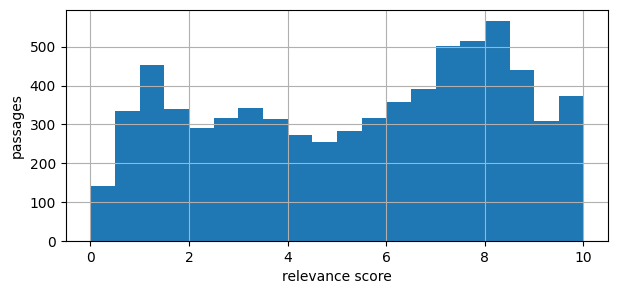

In [8]:
import matplotlib.pyplot as plt
ax = ds.Score.hist(bins=20, figsize=(7, 3))
ax.set_xlabel('relevance score'); ax.set_ylabel('passages'); plt.show()

In [9]:
%%writefile models.py
import torch
import torch.nn as nn

ARCHS = {
    "RNN": (nn.RNN, False),
    "BiRNN": (nn.RNN, True),
    "GRU": (nn.GRU, False),
    "LSTM": (nn.LSTM, False),
}


class SeqRegressor(nn.Module):

    def __init__(self, arch, vocab_size, emb_dim=128, hidden=128, layers=1, dropout=0.3):
        super().__init__()
        cell, bidirectional = ARCHS[arch]
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        kwargs = dict(batch_first=True, num_layers=layers, bidirectional=bidirectional,
                      dropout=dropout if layers > 1 else 0.0)
        if cell is nn.RNN:
            kwargs["nonlinearity"] = "tanh"
        self.rnn = cell(emb_dim, hidden, **kwargs)
        out_dim = hidden * (2 if bidirectional else 1)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(2 * out_dim, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x, lengths):
        emb = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (x != 0).unsqueeze(-1).float()
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        mx = out.masked_fill(mask == 0, -1e4).max(1).values
        h = self.drop(torch.cat([mean, mx], dim=1))
        return 10 * torch.sigmoid(self.head(h)).squeeze(-1)

Overwriting models.py


In [10]:
%%writefile train.py
import itertools
import json
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from nltk.translate.bleu_score import SmoothingFunction, corpus_bleu
from scipy.stats import pearsonr
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split

from models import ARCHS, SeqRegressor
from preprocessing import CLASSES, DATA, discretize

ROOT = Path(__file__).parent
RES = ROOT / "results"
SEED, MAX_LEN, MAX_VOCAB, BATCH = 42, 120, 20000, 64
MAX_EPOCHS, PATIENCE = 10, 2
GRID = {
    "emb_dim": [128],
    "hidden": [64, 128],
    "layers": [1, 2],
    "lr": [2e-3],
    "dropout": [0.3],
}
torch.set_num_threads(4)


def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def build_vocab(token_lists):
    counts = Counter(t for toks in token_lists for t in toks)
    words = [w for w, c in counts.most_common(MAX_VOCAB) if c >= 2]
    return {w: i + 2 for i, w in enumerate(words)}


def encode(token_lists, vocab):
    X = np.zeros((len(token_lists), MAX_LEN), dtype=np.int64)
    L = np.zeros(len(token_lists), dtype=np.int64)
    for i, toks in enumerate(token_lists):
        ids = [vocab.get(t, 1) for t in toks][:MAX_LEN] or [1]
        X[i, : len(ids)] = ids
        L[i] = len(ids)
    return torch.tensor(X), torch.tensor(L)


def batches(X, L, y, shuffle):
    idx = torch.randperm(len(y)) if shuffle else torch.arange(len(y))
    for s in range(0, len(y), BATCH):
        b = idx[s : s + BATCH]
        yield X[b], L[b], y[b]


@torch.no_grad()
def predict(model, X, L):
    model.eval()
    return torch.cat([model(xb, lb) for xb, lb, _ in batches(X, L, torch.zeros(len(L)), False)]).numpy()


def train_one(arch, cfg, vocab_size, train, val):
    seed_all()
    model = SeqRegressor(arch, vocab_size, cfg["emb_dim"], cfg["hidden"], cfg["layers"], cfg["dropout"])
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    loss_fn = nn.MSELoss()
    best, best_state, bad, history = float("inf"), None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        tot = 0.0
        for xb, lb, yb in batches(*train, shuffle=True):
            opt.zero_grad()
            loss = loss_fn(model(xb, lb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(yb)
        train_mse = tot / len(train[2])
        val_mse = mean_squared_error(val[2].numpy(), predict(model, val[0], val[1]))
        history.append({"epoch": epoch, "train_mse": train_mse, "val_mse": val_mse})
        if val_mse < best - 1e-4:
            best, bad = val_mse, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best, history


def label_bleu(y_true_cls, y_pred_cls):
    ref = [CLASSES[c] for c in y_true_cls]
    hyp = [CLASSES[c] for c in y_pred_cls]
    refs = [[ref[i : i + 10]] for i in range(0, len(ref), 10)]
    hyps = [hyp[i : i + 10] for i in range(0, len(hyp), 10)]
    sm = SmoothingFunction().method1
    return (corpus_bleu(refs, hyps, weights=(1, 0, 0, 0), smoothing_function=sm),
            corpus_bleu(refs, hyps, smoothing_function=sm))


def evaluate(y, p):
    yc, pc = [discretize(v) for v in y], [discretize(v) for v in p]
    b1, b4 = label_bleu(yc, pc)
    return {
        "MSE": mean_squared_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
        "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p), "Pearson": pearsonr(y, p)[0],
        "Accuracy(3 classes)": accuracy_score(yc, pc), "F1-macro": f1_score(yc, pc, average="macro"),
        "BLEU-1": b1, "BLEU-4": b4,
    }, (yc, pc)


def main():
    RES.mkdir(exist_ok=True)
    df = pd.read_csv(DATA / "dataset.csv")
    tokens = json.loads((DATA / "tokens.json").read_text("utf-8"))
    y_all = df.Score.to_numpy(dtype=np.float32)
    strat = [discretize(s) for s in y_all]
    idx = np.arange(len(df))
    tr, tmp = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=strat)
    va, te = train_test_split(tmp, test_size=0.5, random_state=SEED, stratify=[strat[i] for i in tmp])
    vocab = build_vocab([tokens[i] for i in tr])
    X, L = encode(tokens, vocab)
    y = torch.tensor(y_all)
    split = lambda ids: (X[ids], L[ids], y[ids])
    train, val, test = split(tr), split(va), split(te)
    print(f"train {len(tr)} | val {len(va)} | test {len(te)} | vocab {len(vocab) + 2}")

    tuning, metrics, histories, preds = [], [], {}, {"Text": df.Text.iloc[te].values, "true": y_all[te]}
    configs = [dict(zip(GRID, v)) for v in itertools.product(*GRID.values())]
    for arch in ARCHS:
        best = None
        for cfg in configs:
            t0 = time.time()
            model, val_mse, hist = train_one(arch, cfg, len(vocab) + 2, train, val)
            dt = time.time() - t0
            tuning.append({"arch": arch, **cfg, "val_RMSE": val_mse ** 0.5, "epochs": len(hist), "seconds": round(dt, 1)})
            print(f"{arch:6s} {cfg} val_RMSE={val_mse ** 0.5:.3f} ({len(hist)} ep, {dt:.0f}s)", flush=True)
            if best is None or val_mse < best[1]:
                best = (model, val_mse, hist, cfg)
        model, _, hist, cfg = best
        torch.save({"state_dict": model.state_dict(), "config": cfg, "vocab": vocab}, RES / f"best_{arch}.pt")
        p = predict(model, test[0], test[1])
        m, (yc, pc) = evaluate(y_all[te], p)
        n_params = sum(t.numel() for t in model.parameters())
        metrics.append({"model": arch, **{k: round(float(v), 4) for k, v in m.items()},
                        "params": n_params, "best_config": json.dumps(cfg)})
        histories[arch], preds[arch] = hist, np.round(p, 2)
        preds[arch + "_cm"] = confusion_matrix(yc, pc, labels=[0, 1, 2])

    pd.DataFrame(tuning).to_csv(RES / "tuning.csv", index=False)
    mdf = pd.DataFrame(metrics)
    mdf.to_csv(RES / "metrics.csv", index=False)
    pd.DataFrame({k: v for k, v in preds.items() if not k.endswith("_cm")}).to_csv(
        RES / "predictions.csv", index=False, encoding="utf-8")
    print(mdf.drop(columns="best_config").to_string(index=False))
    plots(histories, preds, y_all[te])


def plots(histories, preds, y_true):
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
    for ax, (arch, h) in zip(axes, histories.items()):
        ax.plot([e["epoch"] for e in h], [e["train_mse"] for e in h], label="train")
        ax.plot([e["epoch"] for e in h], [e["val_mse"] for e in h], label="val")
        ax.set_title(arch); ax.set_xlabel("epoch")
    axes[0].set_ylabel("MSE"); axes[0].legend()
    fig.tight_layout(); fig.savefig(RES / "loss_curves.png", dpi=120); plt.close(fig)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
    for ax, arch in zip(axes, histories):
        ax.scatter(y_true, preds[arch], s=6, alpha=0.4)
        ax.plot([0, 10], [0, 10], "k--", lw=1)
        ax.set_title(arch); ax.set_xlabel("true score")
    axes[0].set_ylabel("predicted score")
    fig.tight_layout(); fig.savefig(RES / "pred_vs_true.png", dpi=120); plt.close(fig)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, arch in zip(axes, histories):
        cm = preds[arch + "_cm"]
        ax.imshow(cm, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, cm[i, j], ha="center", va="center")
        ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES)
        ax.set_title(arch); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    fig.tight_layout(); fig.savefig(RES / "confusion_matrices.png", dpi=120); plt.close(fig)


if __name__ == "__main__":
    main()

Overwriting train.py


In [11]:
if not Path('results/metrics.csv').exists():
    !python train.py
display(pd.read_csv('results/tuning.csv'))
pd.read_csv('results/metrics.csv')

,arch,emb_dim,hidden,layers,lr,dropout,val_RMSE,epochs,seconds
0,RNN,128,64,1,0.002,0.3,0.762425,10,58.0
1,RNN,128,64,2,0.002,0.3,0.552839,10,75.8
2,RNN,128,128,1,0.002,0.3,0.687229,7,55.3
3,RNN,128,128,2,0.002,0.3,0.575803,9,98.1
4,BiRNN,128,64,1,0.002,0.3,0.625999,10,92.6
5,BiRNN,128,64,2,0.002,0.3,0.877427,5,71.1
6,BiRNN,128,128,1,0.002,0.3,0.682148,8,182.4
7,BiRNN,128,128,2,0.002,0.3,0.863069,6,154.0
8,GRU,128,64,1,0.002,0.3,0.501428,10,113.9
9,GRU,128,64,2,0.002,0.3,0.556515,8,148.5


,model,MSE,RMSE,MAE,R2,Pearson,Accuracy(3 classes),F1-macro,BLEU-1,BLEU-4,params,best_config
0,RNN,0.3413,0.5842,0.4599,0.9583,0.9808,0.9138,0.9069,0.9269,0.8027,885505,"{""emb_dim"": 128, ""hidden"": 64, ""layers"": 2, ""l..."
1,BiRNN,0.4204,0.6484,0.5141,0.9486,0.9781,0.9016,0.8936,0.9231,0.7844,897793,"{""emb_dim"": 128, ""hidden"": 64, ""layers"": 1, ""l..."
2,GRU,0.2450,0.4950,0.3806,0.9701,0.9860,0.9372,0.9325,0.9466,0.8603,972033,"{""emb_dim"": 128, ""hidden"": 128, ""layers"": 1, ""..."
3,LSTM,0.2476,0.4976,0.3903,0.9697,0.9884,0.9222,0.9134,0.9325,0.8196,1137153,"{""emb_dim"": 128, ""hidden"": 128, ""layers"": 2, ""..."


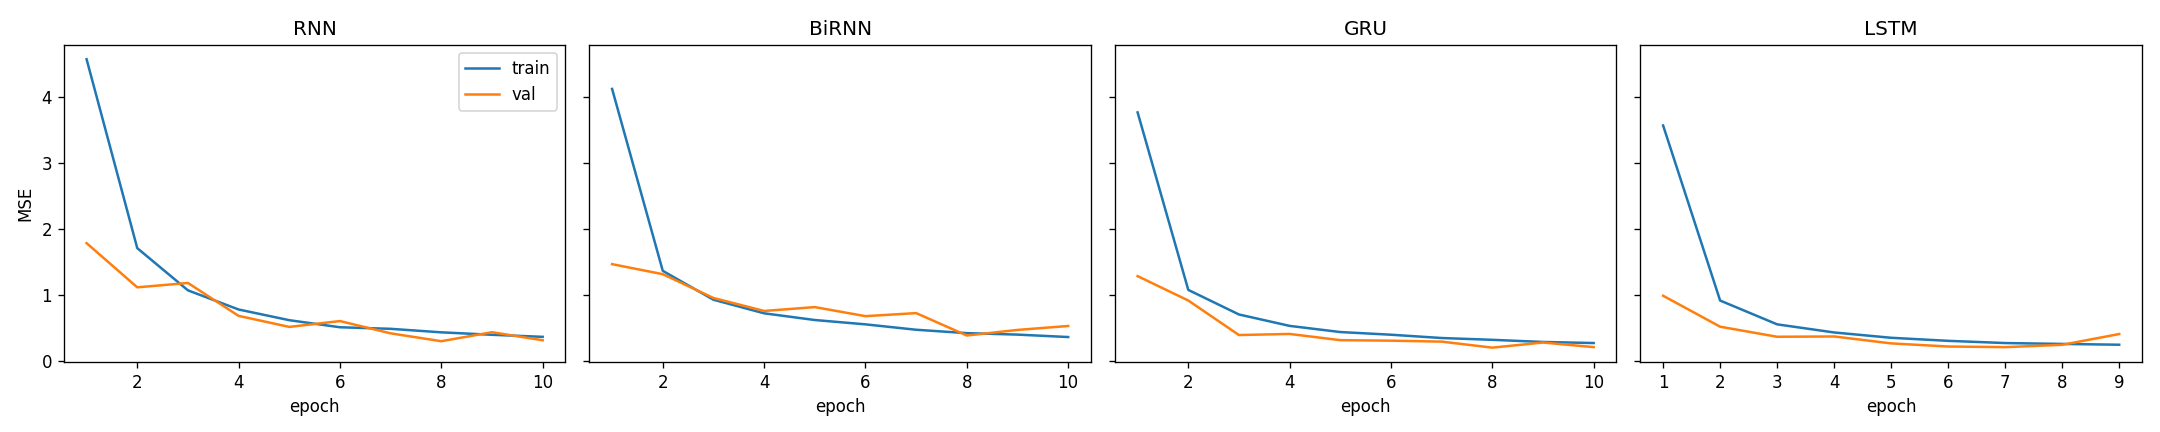

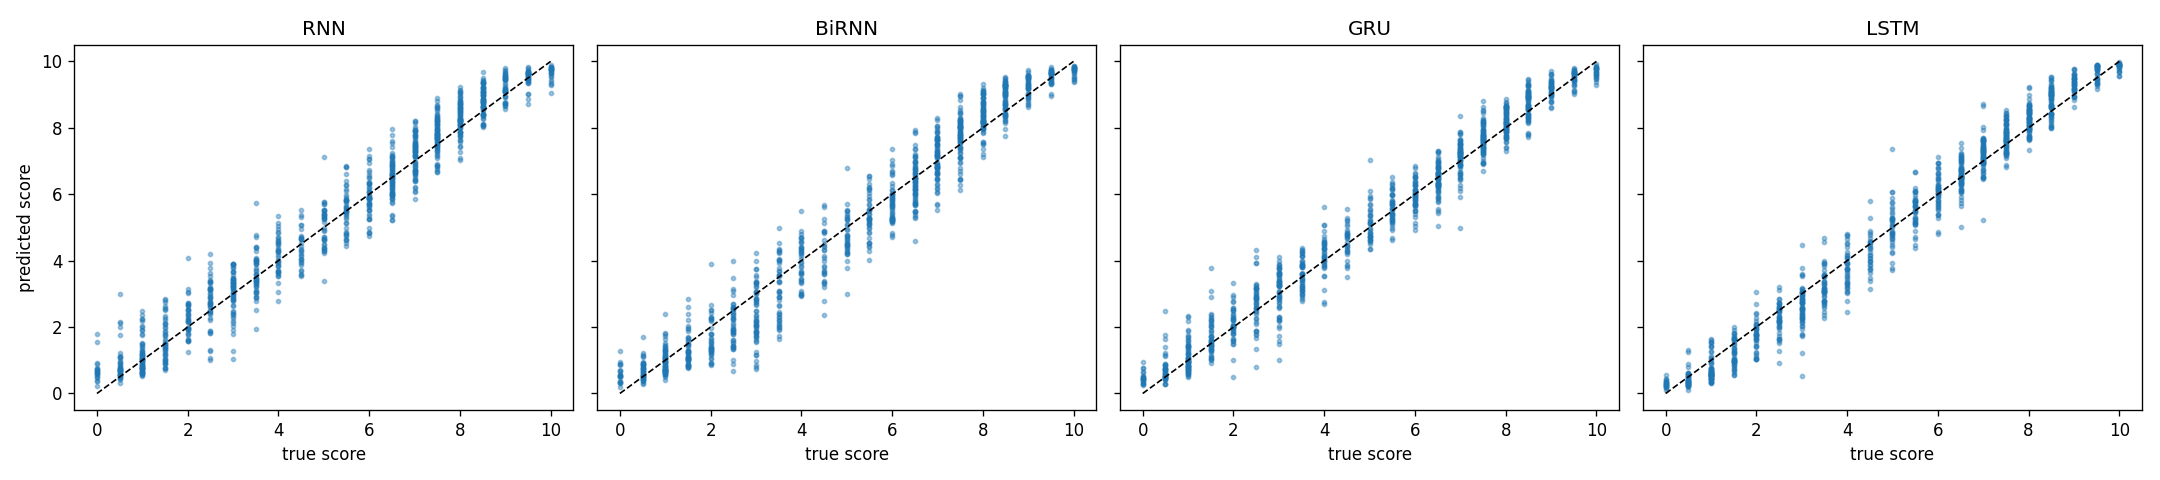

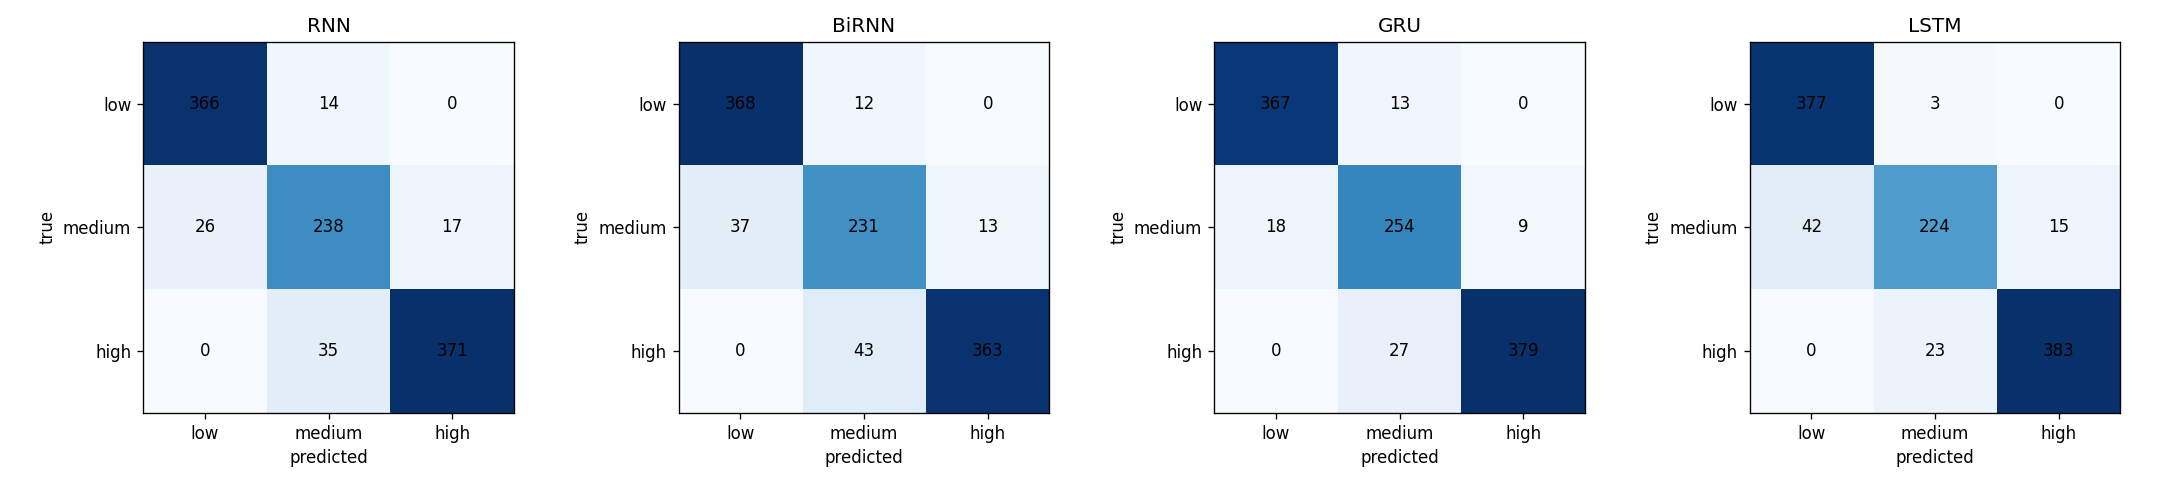

In [12]:
from IPython.display import Image, display
for f in ['loss_curves', 'pred_vs_true', 'confusion_matrices']:
    display(Image(f'results/{f}.png'))

In [13]:
pred = pd.read_csv('results/predictions.csv')
pred.sample(10, random_state=0)

,Text,true,RNN,BiRNN,GRU,LSTM
766,وفي ما يتعلق بأسعار التمور المغربية، نفى حميدي...,8.5,9.35,9.30,9.25,8.98
204,وفي المقابل، أبرز التقرير أن مصر تواجه تحديات ...,8.5,9.20,9.36,8.90,9.10
629,وأوضح فرحان، في تصريح لجريدة هسبريس الإلكتروني...,6.5,6.76,6.71,6.59,6.75
897,وأفادت الفيدرالية البيمهنية المغربية، على لسان...,6.0,5.35,5.21,5.73,6.29
711,وتابع الكاتب: “الوقت كله منذور للأعمال الكبيرة...,0.0,0.76,0.90,0.52,0.27
108,لكن لا يوجد يقين بأن هذه العناصر ستُدرج في الق...,5.0,4.39,4.52,4.83,5.55
319,وتشير المعطيات المعتمدة في إعداد المشروع إلى أ...,9.0,8.78,8.93,8.77,8.83
890,دعت وزارة الداخلية ولاة الجهات وعمال العمالات ...,5.5,4.99,4.69,5.19,5.28
320,وكان وزير التربية الوطنية، محمد نبيل بنعبد الل...,4.5,4.66,4.49,4.80,4.07
545,بلغت احتياطيات صناديق التقاعد المغربية 340.8 م...,8.0,7.99,7.96,7.78,7.95
